# **Algunas visualizaciones de attention**

En este notebook exploraremos algunas visualizaciones del modelo de attention a través de [BERT](https://huggingface.co/docs/transformers/model_doc/bert).

BERT es un modelo transformer **encoder-only** ,esto significa que solo usa la mitad "de entender" de la arquitectura completa (sin decoder, sin
generación de texto palabra por palabra).

Fue entrenado por Google, ya con sus pesos ajustados
(pre-entrenado) sobre grandes cantidades de texto

No lo vamos a entrenar nosotros, solo vamos a usar un
modelo que ya aprendió a calcular attention de forma útil.

`bert-base-uncased`:
- **base** = el tamaño más chico de BERT (12 capas,
  12 cabezas por capa)
- **uncased** = no distingue mayúsculas de minúsculas
  ("The" y "the" se tratan igual)

La primera vez que corran esta celda, va a descargar
el modelo desde [HuggingFace](https://huggingface.co/) (una plataforma que aloja modelos pre-entrenados), por lo que puede tardar un poco, es normal.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
!pip install bertviz -q #se corre solo una vez!


In [2]:
#se corre solo una vez para cargar el modelo
from bertviz import head_view
from transformers import BertTokenizer, BertModel

model = BertModel.from_pretrained('bert-base-uncased', output_attentions=True)
tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')

print("Modelo cargado, listo para usar")

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Modelo cargado, listo para usar


# 1. Multi-head attention

El transformer no hace attention una sola vez, la repite en varias capas apiladas

- Layer = en cuál de esas capas estás mirando
(BERT-base tiene 12 capas, apiladas una sobre otra)

- Head = dentro de esa capa, cuál cabeza de multi-head
attention estás mirando
(BERT-base tiene 12 cabezas, en paralelo, dentro de cada capa)

12 capas × 12 cabezas = 144 "vistas" de attention distintas
en todo el modelo

La cabeza roja en la Layer 3 no tiene relación directa
con la cabeza roja en la Layer 8, son patrones independientes

In [5]:
#frase = "The trophy didn't fit in the suitcase because it was too big"
#frase = "The city council refused the demonstrators a permit because they feared violence"
#frase = "The animal didn't cross the street because it was too tired"
frase = "The dog chased the cat until it got tired"

inputs = tokenizer.encode(frase, return_tensors='pt')
outputs = model(inputs)
attention = outputs.attentions
tokens = tokenizer.convert_ids_to_tokens(inputs[0])

head_view(attention, tokens)

<IPython.core.display.Javascript object>

### **Actividad**

1. Escribe tu propia oración con una palabra ambigua
   (que podría referirse a más de una cosa). Reemplaza
   el texto en "oracion" en la celda de arriba

2. Antes de correr, predice a mano a qué palabra debería
   atender esa palabra ambigua

3. Corre la celda. Haz clic en la palabra ambigua en el
   visualizador para ver las líneas de atención

4. Compara: ¿acertaste? ¿Qué cabeza (color) capturó la
   relación que esperabas?

**RESPUESTAS:**
1. la frase es "The bottle fell off the table because it was full of water". La palabra ambigua viene a ser "it", puede referirse a dog o a cat
2. “it” debería atender a dog, el que persigue corre más y se cansa más. 
3. En el visuaizador, al seleccionar "it", la cabeza verde de la capa 6 mostró la línea más fuerte hacia "dog".
4. La predicción fue correcta. La relación no apareció en todas las cabezas: varias apuntaban a [SEP], a la puntuación o a palabras vecinas. Solo una cabeza específica (verde en una capa intermedia) capturó la correferencia “it” --> “dog”.

# 2. Self-attention con pesos reales

Ahora usamos las matrices W_Q, W_K, W_V que BERT realmente
aprendió durante su entrenamiego — el mismo cálculo que ya
programaron a mano, pero con pesos entrenados en vez de
aleatorios.

Prueben cambiar `num_capa` (0 a 11) y comparen los patrones:

- Capas tempranas (0-1): attention más local, o colapsando
  hacia tokens especiales como [CLS]
- Capas intermedias/profundas: patrones distintos, pero
  cuidado: este código combina las 12 cabezas en un solo
  promedio, así que relaciones específicas pueden diluirse acá

Si el resultado no muestra una relación "clara" como en
BertViz, no es un error: significa que esa relación vivía
en UNA cabeza específica, no en el promedio de las 12.


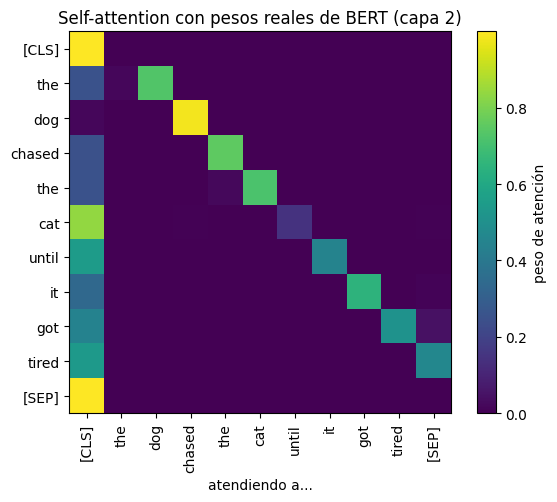

In [18]:
# Elegir qué capa mirar (0 a 11)
num_capa = 2

inputs = tokenizer(frase, return_tensors='pt') #tokenizador de la frasw
outputs = model(**inputs, output_hidden_states=True) #guarda el resultado de cada capa

# hidden_states[0] = embeddings originales (entrada a la capa 0)
# hidden_states[N] = salida de la capa N-1 (entrada a la capa N)
entrada_a_esta_capa = outputs.hidden_states[num_capa].detach().numpy()[0]
tokens = tokenizer.convert_ids_to_tokens(inputs['input_ids'][0])

capa = model.encoder.layer[num_capa].attention.self
#matrices de pesos reales ya entrenados de BERT
W_Q_real = capa.query.weight.detach().numpy()
W_K_real = capa.key.weight.detach().numpy()
W_V_real = capa.value.weight.detach().numpy()

# @ en numpy es el operador de multiplicación de matrices
Q = entrada_a_esta_capa @ W_Q_real.T
K = entrada_a_esta_capa @ W_K_real.T
V = entrada_a_esta_capa @ W_V_real.T

d = Q.shape[1]
#producto punto escalado de attention
scores = (Q @ K.T) / np.sqrt(d)
exp_scores = np.exp(scores - scores.max(axis=1, keepdims=True)) #softmax
pesos_atencion = exp_scores / exp_scores.sum(axis=1, keepdims=True)

#visualización
plt.figure(figsize=(6,5))
plt.imshow(pesos_atencion, cmap="viridis")
plt.xticks(range(len(tokens)), tokens, rotation=90)
plt.yticks(range(len(tokens)), tokens)
plt.xlabel("atendiendo a...")
plt.colorbar(label="peso de atención")
plt.title(f"Self-attention con pesos reales de BERT (capa {num_capa})")
plt.tight_layout()
plt.show()

### **Observe y responda**

- ¿Hacia qué palabra(s) se concentra la mayor parte de la
  atención en esta capa?
- ¿Es un patrón interpretable (relación de significado) o
  parece attention "colapsando" hacia puntuación/tokens
  especiales?
- Compare con el resultado de otra capa: ¿qué cambió?



**RESPUESTAS:**
- Depende de la capa. Capa 0, la atención es casi diagonal, o sea que cada token se mira principalmente a sí mismo, con algo de dispersión hacia otros tokens.
Capa 2, sigue siendo diagonal, pero cada token también atiende a la palabra siguiente en la oración. Capas 6 y 11, casi toda la atención se concentra en el token [SEP], sin importar qué palabra esté mirando. 
- En las capas tempranas (0 y 2) el patrón es más de posición que de significado, los tokens se miran a sí mismos o a sus vecinos inmediatos. Es útil, porque así BERT va armando el contexto local, pero todavía no es una relación de significado como “it” --> “dog”. En las capas 6 y 11 la atención colapsa hacia [SEP]. No es una relación de significado, [SEP] funciona como un “lugar por defecto” donde mandar la atención cuando no hay nada importante que mirar.
- A medida que se sube de capa, la atención pasa de ser local (uno mismo y/o el vecino) a estar concentrada en [SEP]. Lo interesante es que en BertViz, en la capa 6, la cabeza verde sí mostraba la relación “it” --> “dog”, pero aquí, en esa misma capa, no se ve. Esto pasa porque este código combina las 12 cabezas en un solo cálculo, la mayoría de las cabezas mandan su atención a [SEP] o [CLS] y eso tapa la señal de la única cabeza que captaba la correferencia. Es decir, las relaciones de significado viven en cabezas específicas.

# 3. Clasificador de sentimiento

`pipeline("sentiment-analysis")` descarga un modelo ya
entrenado específicamente para una tarea: decidir si un
texto es POSITIVO o NEGATIVO.

Por dentro sigue siendo un transformer (parecido a BERT), con el mismo mecanismo de attention, pero fue
afinado (fine-tuning) con miles de ejemplos de texto
etiquetados como positivo/negativo, hasta aprender a
distinguir el tono de un texto.

El resultado incluye un "label" (POSITIVE o NEGATIVE) y
un "score" (qué tan seguro está el modelo de esa clasificación).

En este caso, usaremos DistilBERT, que está basado en BERT pero es una versión más comprimida.

- BERT-base: 12 capas, 768 dimensiones, ~110 millones de parámetros

- DistilBERT: 6 capas (la mitad), misma dimensión (768),
                 ~66 millones de parámetros
                 → ~40% más chico, ~60% más rápido,
                 conservando ~97% del rendimiento de BERT
                 en varias tareas

In [20]:
from transformers import pipeline

clasificador = pipeline("sentiment-analysis", model="distilbert-base-uncased-finetuned-sst-2-english") #modelo fine-tuned para análisis de sentimiento

frases = [
    # Clara
    "I love this class, it's amazing",
    "This was the worst movie I've ever seen",
    # Ambigua
    "The movie was okay, nothing special",
    "I went to the store today",
    # Sarcasmo / ironía
    "Great, another Monday",
    "Oh wonderful, my code crashed again",
    # Doble negación
    "The food was not bad at all",
]

for f in frases:
    r = clasificador(f)[0]
    print(f"{r['label']:8} {r['score']:.3f}  |  {f}")

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

POSITIVE 1.000  |  I love this class, it's amazing
NEGATIVE 1.000  |  This was the worst movie I've ever seen
NEGATIVE 0.995  |  The movie was okay, nothing special
NEGATIVE 0.964  |  I went to the store today
POSITIVE 1.000  |  Great, another Monday
POSITIVE 1.000  |  Oh wonderful, my code crashed again
POSITIVE 0.998  |  The food was not bad at all


### **Actividad**

1. Cambie "frase" por algo suyo; pueden probar una
   frase claramente positiva, una negativa, y una ambigua
   o irónica (ej. "great, another Monday")

2. Observe el "score" (la probabilidad), no solo el
   label. ¿Qué tan seguro está el modelo?

3. Pruebe una oración con sarcasmo o doble sentido.
   ¿El modelo lo detecta, o falla?

**RESPUESTAS:**
1. La frase claramente positiva y la claramente negativa (primera y segunda) salen como POSITIVE y NEGATIVE respectivamente, ambas con score 1.000. Correcto. Las frases neutras o ambiguas salieron NEGATIVE con mucha seguridad: “The movie was okay, nothing special” con 0.995 y “I went to the store today” con 0.964. La segunda es simplemente un hecho, sin ningún sentimiento.
2. Casi siempre está muy seguro (scores sobre 0.96), incluso cuando se equivoca o cuando la frase no tiene sentimiento. Esto pasa porque el modelo solo tiene dos opciones y el softmax lo obliga a repartir la probabilidad entre esas dos. Por eso un score alto no significa que la respuesta sea correcta, solo que el modelo eligió uno de los dos lados.
3. No, “Great, another Monday” y “Oh wonderful, my code crashed again” salieron POSITIVE con score 1.000, cuando claramente son quejas. El modelo se deja llevar por palabras con carga positiva (great, wonderful) y no capta la ironía, que depende del contexto y del conocimiento previo de las expresiones. En cambio, “The food was not bad at all” salió POSITIVE (0.998), que es correcto. El modelo entiende la negación de “bad”, lo que muestra que la atención le permite combinar palabras y no solo mirarlas por separado. El sarcasmo es más difícil porque necesita mucha interpretación.

###

# 4. Extrayendo embeddings de una oración

`pipeline("feature-extraction")` toma un texto y devuelve
un vector numérico para cada token de esa oración, que es la
representación final que BERT genera después de procesar
toda la oración a través de sus 12 capas.

Estos vectores capturan tanto el significado de cada palabra
como el contexto de las palabras que la rodean. Se usan,
por ejemplo, para comparar qué tan similares son dos textos,
o como entrada para otro modelo que necesite trabajar con
texto ya convertido a números.

El resultado es una matriz: una fila por token, y cada fila
tiene 768 números (el tamaño del vector que usa BERT-base).



In [21]:
extractor = pipeline("feature-extraction", model="bert-base-uncased")

embedding = extractor("The animal didn't cross the street because it was too tired")
print("Forma del embedding:", len(embedding[0]), "(filas) x", len(embedding[0][0]), "(columnas)")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Forma del embedding: 15 (filas) x 768 (columnas)


In [ ]:
tokens = tokenizer.tokenize("The animal didn't cross the street because it was too tired")
print(tokens)
print("Cantidad (sin CLS/SEP):", len(tokens))
#Para entender como funcionan los tokens

['the', 'animal', 'didn', "'", 't', 'cross', 'the', 'street', 'because', 'it', 'was', 'too', 'tired']
Cantidad (sin CLS/SEP): 13


## Qué significa la forma del embedding

**X (filas):** es la cantidad de tokens en que quedó
dividida la oración. No es necesariamente la cantidad de
palabras, BERT tokeniza así:

- Agrega [CLS] al principio y [SEP] al final (2 tokens extra)
- Puede partir una palabra en varios pedazos si no la
  reconoce completa en su vocabulario (ej. "didn't" puede
  quedar dividido en "didn" + "'" + "t")

Por eso el conteo final de tokens casi nunca coincide con
contar palabras separadas por espacios.

**768 (columnas):** es el tamaño del vector de embedding
que BERT-base usa para representar cada token. Es un
número fijo, decidido por quienes diseñaron y entrenaron
este modelo específico, no es un valor universal, otros
modelos usan otros tamaños (BERT-large usa 1024, por
ejemplo).

**Entonces la matriz completa (X x 768)** es: por cada uno
de los 11 tokens de la oración, un vector de 768 números
que lo representa

### El embedding tiene forma 15 × 768: 15 tokens (11 palabras, +2 porque ‘didn’t’ se divide en 3 piezas, +2 por [CLS] y [SEP]) y 768 dimensiones por token, que es el tamaño fijo de BERT-base. El número de tokens no coincide con el de palabras por la forma en que BERT tokeniza.

# 5. Embeddings similares

Este código extrae el vector (embedding) que BERT genera
para la palabra "bank" en dos oraciones distintas:

- "I deposited money at the bank" (banco financiero)
- "We sat by the river bank" (orilla de un río)

`obtener_embedding_palabra` tokeniza la oración, la pasa
por el modelo, encuentra la posición exacta de la palabra
"bank" entre los tokens, y devuelve su vector final.

Después se calcula la similaridad coseno entre ambos
vectores, el resultado es un número entre 0 y 1 que mide qué tan parecidos
son. 1 significa idénticos, 0 significa sin relación.

Si el resultado sale bajo, significa que BERT generó
representaciones distintas para la misma palabra, según
el contexto de cada oración.

In [23]:
def obtener_embedding_palabra(frase, palabra_objetivo):
    inputs = tokenizer(frase, return_tensors='pt')
    outputs = model(**inputs)
    tokens = tokenizer.convert_ids_to_tokens(inputs['input_ids'][0])
    idx = tokens.index(palabra_objetivo)
    return outputs.last_hidden_state[0, idx].detach().numpy()

frase1 = "I deposited money at the bank"
frase2 = "We sat by the river bank"

emb1 = obtener_embedding_palabra(frase1, "bank")
emb2 = obtener_embedding_palabra(frase2, "bank")

# Similaridad coseno: 1 = idénticos, 0 = sin relación
similaridad = np.dot(emb1, emb2) / (np.linalg.norm(emb1) * np.linalg.norm(emb2))
print(f"Similaridad entre 'bank' (financiero) y 'bank' (río): {similaridad:.3f}")

Similaridad entre 'bank' (financiero) y 'bank' (río): 0.726


In [24]:
#Corre todo de una sola vez
def similaridad(f1, f2, palabra):
    e1 = obtener_embedding_palabra(f1, palabra)
    e2 = obtener_embedding_palabra(f2, palabra)
    return np.dot(e1, e2) / (np.linalg.norm(e1) * np.linalg.norm(e2))

pruebas = [
    # (frase1, frase2, palabra, tipo)
    ("The bat flew out of the cave at night",
     "He hit the ball with a wooden bat", "bat", "DISTINTO significado"),
    ("The bat flew out of the cave at night",
     "A small bat was hanging from the tree", "bat", "MISMO significado"),

    ("Flowers bloom in the spring",
     "The spring in the mattress is broken", "spring", "DISTINTO significado"),
    ("Flowers bloom in the spring",
     "We go hiking every spring", "spring", "MISMO significado"),

    ("I deposited money at the bank",
     "We sat by the river bank", "bank", "DISTINTO significado"),
    ("I deposited money at the bank",
     "The bank approved my loan", "bank", "MISMO significado"),
]

for f1, f2, palabra, tipo in pruebas:
    s = similaridad(f1, f2, palabra)
    print(f"{palabra:7} {tipo:22} {s:.3f}")

bat     DISTINTO significado   0.481
bat     MISMO significado      0.841
spring  DISTINTO significado   0.308
spring  MISMO significado      0.739
bank    DISTINTO significado   0.726
bank    MISMO significado      0.545


### **Actividad**

1. Elija una palabra en inglés con dos significados
   distintos (ej. "bat" — animal / objeto deportivo,
   "spring" — estación / resorte, "match" — fósforo / partido)

2. Escriba dos oraciones donde esa palabra tenga cada
   significado

3. Reemplace `frase1`, `frase2` y `palabra_objetivo` en
   el código con las suyas, y corra la celda

4. ¿qué tan alta o baja salió la
   similaridad? Tiene sentido?

5. Pruebe también con la **misma** palabra usada dos veces
   con el **mismo** significado, en oraciones distintas
   (ej. "bank" financiero en dos contextos distintos).
   ¿La similaridad sale más alta que en el caso ambiguo?




**RESPUESTAS:**
1. Hecho
2. Hecho
3. Hecho
4. Para “bat” (0.481) y “spring” (0.308), la similaridad entre significados distintos salió baja, lo que tiene sentido, pues BERT generó representaciones diferentes según el contexto, a pesar de ser la misma palabra.
5. Con el mismo significado la similaridad fue más alta en “bat” (0.841) y “spring” (0.739), como se esperaba. Sin embargo, “bank” mostró lo contrario: el par de significados distintos (0.726) superó al de significado igual (0.545). Esto ocurre porque en “at the bank” y “river bank” la palabra cumple el mismo rol (final de la oración, después de una preposición), por lo que BERT se confunde, mientras que en “The bank approved my loan” es el sujeto. Esto muestra que los embeddings de BERT capturan no solo el significado, sino también la posición y la función de la palabra, y que puede ocurrir que esa información domine sobre el significado.

# 6. Context size

Este código muestra el límite real de tokens que BERT puede
procesar de una vez (`tokenizer.model_max_length`).

Después genera un texto artificialmente largo (la misma
oración repetida 1000 veces) y cuenta cuántos tokens resultan
al tokenizarlo.

Si esa cantidad supera el límite del modelo, lo va a indicar
explícitamente. Esto muestra de forma concreta algo que ya
vimos en la teoría: el contexto no es ilimitado, y un texto
real puede superarlo fácilmente.

In [25]:
# Ver el context size real del modelo que ya tienen cargado
print("Context size máximo de BERT:", tokenizer.model_max_length)

# Generar un texto artificialmente largo y ver qué pasa
texto_largo = "El gato come pescado. " * 1000  # se repite 1000 veces

tokens = tokenizer.encode(texto_largo)
print("Cantidad de tokens generados:", len(tokens))

if len(tokens) > tokenizer.model_max_length:
    print("¡Este texto EXCEDE el límite de contexto del modelo!")

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (8002 > 512). Running this sequence through the model will result in indexing errors


Context size máximo de BERT: 512
Cantidad de tokens generados: 8002
¡Este texto EXCEDE el límite de contexto del modelo!


# **Para las siguientes actividades, use el LLM de su preferencia (ChatGPT, Claude, Gemini, etc)**

## **Actividad: poniendo a prueba el context size**

1. Al empezar una conversación nueva, dile al modelo un
   dato inventado y específico, por ejemplo:
   "Mi número de la suerte es 4173. Recuérdalo."

2. Pégale un texto largo de relleno (puede ser un capítulo
   de Wikipedia, un paper, cualquier texto de varios miles
   de palabras) y pídele que lo resuma.

3. Sigue conversando sobre OTROS temas durante varios
   mensajes más (5-10 intercambios), sin mencionar el
   número de la suerte.

4. Al final, pregúntale: "¿cuál era mi número de la suerte?"

5. ¿lo recordó? ¿Lo recordó mal? Si la conversación
se hizo muy larga, ¿en qué momento empezó a fallar?


**Nota**: los modelos actuales tienen ventanas de contexto
bastante grandes, así que es posible que el modelo SÍ
recuerde el número incluso con texto de relleno largo.
Si eso pasa, pruebe agregando más texto
de relleno, o una conversación más larga, para ver si en
algún punto empieza a fallar.

**RESPUESTA:**
- El modelo recordó el número correctamente, incluso después de un texto largo y varios mensajes sobre otros temas. Esto ocurre porque los LLM actuales tienen ventanas de contexto de cientos de miles de tokens, muchísimo más que los 512 de BERT. Toda la conversación cabía dentro del contexto, así que el modelo pudo recordar el número. Para que fallara habría que superar ese límite, lo que requeriría una conversación enorme. Aun así, el límite existe si la conversación lo supera, la información más antigua queda fuera y el modelo ya no puede acceder a ella.

## **Actividad: ¿Pensar paso a paso mejora las respuestas de un LLM?**

Los modelos de lenguaje pueden equivocarse incluso en tareas aparentemente sencillas, como contar letras. Sin embargo, generar pasos intermedios y verificar sus resultados puede mejorar la precisión (*Chain-of-Thought*).

**1.** En una conversación nueva con un LLM, escriban:

> ¿Cuántas veces aparece la letra «r» en la palabra «ferrocarrilero»? Responde solamente con el número.

**2.** En otra conversación nueva, utilicen el mismo modelo, pero ahora escriban:

> ¿Cuántas veces aparece la letra «r» en la palabra «ferrocarrilero»? Enumera primero las posiciones de cada «r», verifica el conteo y luego entrega el resultado.

**3.** Repitan el experimento con otras palabras de su elección. Comparen los resultados y comprueben las respuestas correctas.

**Para discutir:**

- ¿Observaron diferencias entre las dos estrategias?
- ¿Por qué generar pasos intermedios podría ayudar a resolver el problema?
- ¿Es lo mismo pedirle a un LLM que razone paso a paso que utilizar un *reasoning model*?
- ¿Una explicación detallada garantiza que la respuesta sea correcta?

**Opcional:** repitan el experimento utilizando un modelo Instant y uno de razonamiento. ¿Encuentran diferencias?

*Nota:* No es necesario que el modelo cometa errores. El objetivo es investigar cómo influye la estrategia de generación en los resultados y qué relación tiene con Chain-of-Thought y test-time compute.

**RESPUESTAS:**
- No, el modelo acertó con ambas estrategias (5 letras ‘r’ en ‘ferrocarrilero’). La diferencia estuvo en la forma, el primer prompt respondió solo con el número, sin mostrar cómo llegó a él, y con el segundo enumeró las posiciones y verificó el conteo, así que el resultado se puede revisar paso a paso. Esto puede deberse a la buena calidad del modelo, o a que la palabra era fácil de analizar.
- LLM no ve letras sino tokens, igual que vimos con BERT. Contar letras dentro de un token es difícil, al escribir las posiciones una por una, el modelo genera texto que después puede mirar con attention, y el problema se convierte en tareas pequeñas y verificables. Además, cada token generado implica más cómputo antes de llegar a la respuesta final.
- No, pedirlo es una técnica de prompt, el modelo razona porque se lo pedimos, y lo hace visible en la respuesta. Un reasoning model fue entrenado específicamente para razonar antes de responder, osea lo hace siempre, puede revisar y corregir sus propios pasos, y suele usar más cómputo.
- No, el modelo puede escribir pasos que se ven convincentes y aun así equivocarse (por ejemplo, saltarse una letra). Incluso puede llegar a la respuesta correcta con un razonamiento incorrecto. La explicación ayuda, pero no reemplaza verificar el resultado.